# 🧪 LAB: Non-linear Dimensionality Reduction — t-SNE and UMAP

Over the past few weeks, we have explored how to handle non-linear relationships, mainly in the context of classification and regression tasks.

However, sometimes the first and most important step is to **visualize** the data — to gain intuition, spot structure, or detect outliers — even before any predictive modeling. You have already seen how PCA can help with this, but as we discussed this week, (ordinary) PCA is a linear method and may not capture non-linear patterns in the data effectively.

In this lab, you will learn about two popular **non-linear dimensionality reduction techniques** that are typically used for **data visualization**:  
- **t-SNE (t-distributed Stochastic Neighbor Embedding)**  
- **UMAP (Uniform Manifold Approximation and Projection)**

You will apply and compare these methods on two datasets:
- A simple biological dataset: Palmer Penguins
- A high-dimensional human genotype dataset from the 1000 Genomes Project (adapted from Diaz-Papkovich *et al.*, 2019)

---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


In [5]:
#NAME(s) = "Group 11 Setion 1"

## 1. Background Reading (20 points)

Begin by reading **Section 5.3: t-SNE and UMAP for High-Dimensional Data** from the [*Machine Learning Hero* book](https://www.oreilly.com/library/view/machine-learning-hero/9781837025015/), which is available through UVA’s subscription to O’Reilly.

After reading, discuss with your group and respond to the following questions:

a. **Why might we choose t-SNE or UMAP over PCA for dimensionality reduction?**  
t-SNE and UMAP are dimensionality reduction technqus meant to capture finer patterns within non-linear data, while also making them intepretable for humans. Therefore, we'd use t-SNE or UMAP on non-linear data.

b. **Summarize the strengths and weaknesses of t-SNE and UMAP.**  
What are the key differences between the two methods? In what situations might you prefer one over the other?
t-SNE excels 

c. **What are the main hyperparameters of each method, and what role do they play?**  
Describe how these hyperparameters affect the behavior and output of the algorithms.


YOUR TEXT HERE

## 2. Experiment with the Palmer Penguins Dataset (Toy Example) (50 points)

To get hands-on experience, you will begin by applying dimensionality reduction techniques to a small and interpretable dataset: Palmer Penguins.

Before you begin coding, read the official documentation for the following methods:

- [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html) — from `sklearn.decomposition`
- [t-SNE](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html) — from `sklearn.manifold`
- [UMAP](https://umap-learn.readthedocs.io/en/latest/basic_usage.html) — from the `umap-learn` package

After reviewing the documentation, complete the following tasks:

a. Load the Palmer Penguins dataset as demonstrated in the [UMAP documentation](https://umap-learn.readthedocs.io/en/latest/basic_usage.html#penguin-data).  

Select the following numerical features:

- `bill_length_mm`  
- `bill_depth_mm`  
- `flipper_length_mm`  
- `body_mass_g`

Then, **standardize** these features so that each has zero mean and unit variance.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap
from sklearn.preprocessing import StandardScaler

/Users/pacoherrera/Downloads/DataScience/Semester 3/Machine Learning/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [7]:
# a
penguins = pd.read_csv("https://raw.githubusercontent.com/allisonhorst/palmerpenguins/c19a904462482430170bfe2c718775ddb7dbb885/inst/extdata/penguins.csv")
penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [8]:
data = penguins[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]]
# standardize so that each has zero mean and unit variance -- standard scaler
data.info() # 2 rows are missing 
X = data.dropna() # dropping rows with missing values
X_scaled = StandardScaler().fit_transform(X) # then fit transform
labels = penguins.loc[X.index, "species"].values # for visualization
    

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   bill_length_mm     342 non-null    float64
 1   bill_depth_mm      342 non-null    float64
 2   flipper_length_mm  342 non-null    float64
 3   body_mass_g        342 non-null    float64
dtypes: float64(4)
memory usage: 10.9 KB


b. Apply **PCA**, **t-SNE**, and **UMAP** to reduce the selected features to **2 dimensions**.

Then, for each method:
- Create a **scatter plot** of the 2D projection.
- Use a different color to represent each **species** in the dataset.

This will help you visually assess how well each method separates the species in the reduced space.

*N.B.* You may need to first install `UMAP-learn`. Follow the [documentation](https://umap-learn.readthedocs.io/en/latest/index.html) for that.

/Users/pacoherrera/Downloads/DataScience/Semester 3/Machine Learning/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


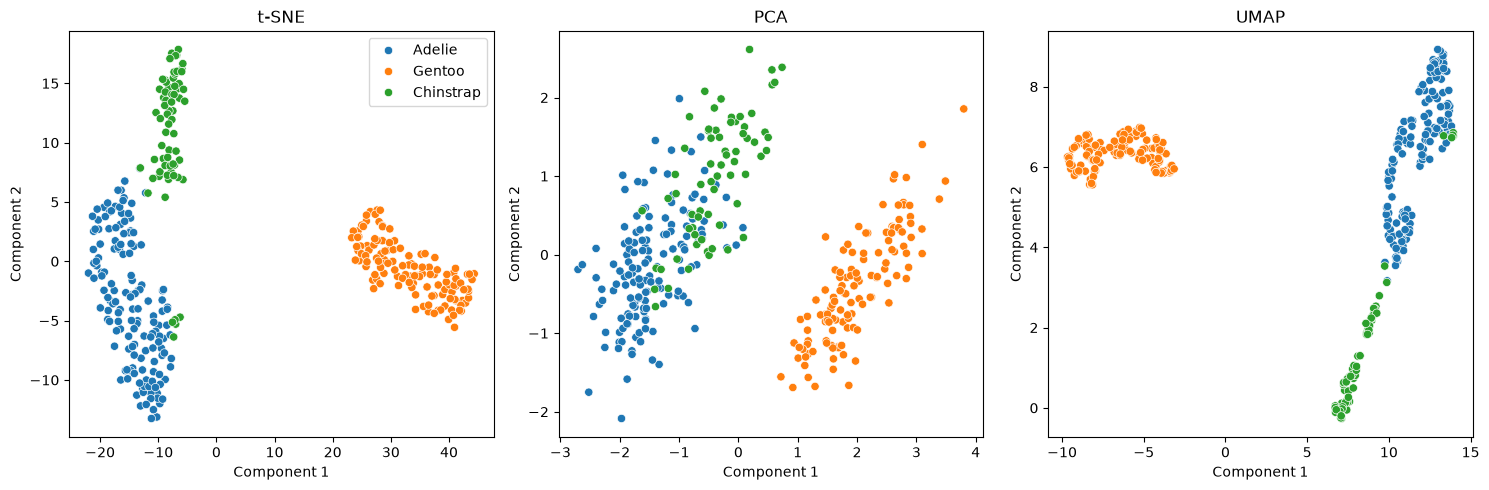

In [14]:
# b
tsne = TSNE(n_components=2, random_state=42)
    # perplexity default=30
    # all default params for now
#TSNE()
X_tsne = tsne.fit_transform(X_scaled)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

umap_model = umap.UMAP(n_components=2, random_state=42)
    # just use default params for now
X_umap = umap_model.fit_transform(X_scaled)

embeddings = {"t-SNE": X_tsne, "PCA": X_pca, "UMAP": X_umap}
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, emb) in zip(axes, embeddings.items()):
    sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=labels, ax=ax, legend=(name == "t-SNE"))
    ax.set_xlabel("Component 1")
    ax.set_ylabel("Component 2")    
    ax.set_title(name)
plt.tight_layout()
plt.show()


c. Analyze the resulting plots and describe the main patterns you observe.

- Which method produces the most visually separable clusters?
- Are there any species that overlap in one method but not in others?
- What might explain these differences in how the data is projected?

Elaborate on your observations and compare the strengths and limitations of each method based on this toy example.


It appears that t-SNE and UMAP have similar distinction in their clusters due to their tighter clusers when compared to PCA, however, all three have species overlap in Adelie and Chinstrap penguins. To explain the differences, it is necessary to look at the methods of optimization of each model. PCA is linear and global (uses all the data at once)--it projects onto two orthogonal directions of maximum variance, preserving large-scale distances, but can only show distinct clusters for groups that differ on those directions. t-SNE and UMAP are nonlinear and local (only look at each point's neighboring points), and both prioritize keeping each point near its neighbor so that clusters are tighter and better reflect patterns that a linear projection cannot. These differentiations are what reflect the differences in how the data is projected. While PCA excels in interpretability, it cannot capture non-linear structure. t-SNE's strenghts are in its cluster separations, however, its cluster sizes and between-cluster distances are not interpretable. UMAP is fast, good at cluster separations, and better at preserving data structure when compared to t-SNE, however, its distances are still not as meaningful as PCA's.

d. For **t-SNE** and **UMAP**, explore how different hyperparameter settings affect the resulting 2D projections.

- For **t-SNE**, vary the `perplexity` parameter (e.g., 5, 30, 50).
- For **UMAP**, vary the `n_neighbors` parameter (e.g., 5, 15, 50) and optionally `min_dist`.
- Keep `random_state` fixed across all runs so that differences between projections are due primarily to changes in the hyperparameters rather than random initialization.

For each configuration:
- Plot the resulting 2D projection.
- Use color to represent species.

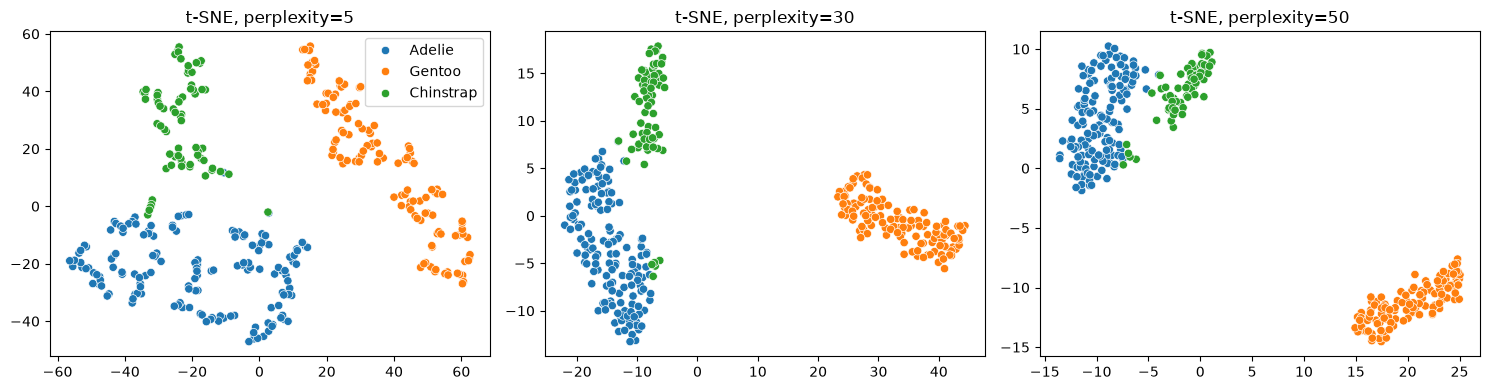

/Users/pacoherrera/Downloads/DataScience/Semester 3/Machine Learning/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/pacoherrera/Downloads/DataScience/Semester 3/Machine Learning/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/pacoherrera/Downloads/DataScience/Semester 3/Machine Learning/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/pacoherrera/Downloads/DataScience/Semester 3/Machine Learning/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/pacoherrera/Downloads/DataScience/Semester 3/Machine Learning/.venv/lib/p

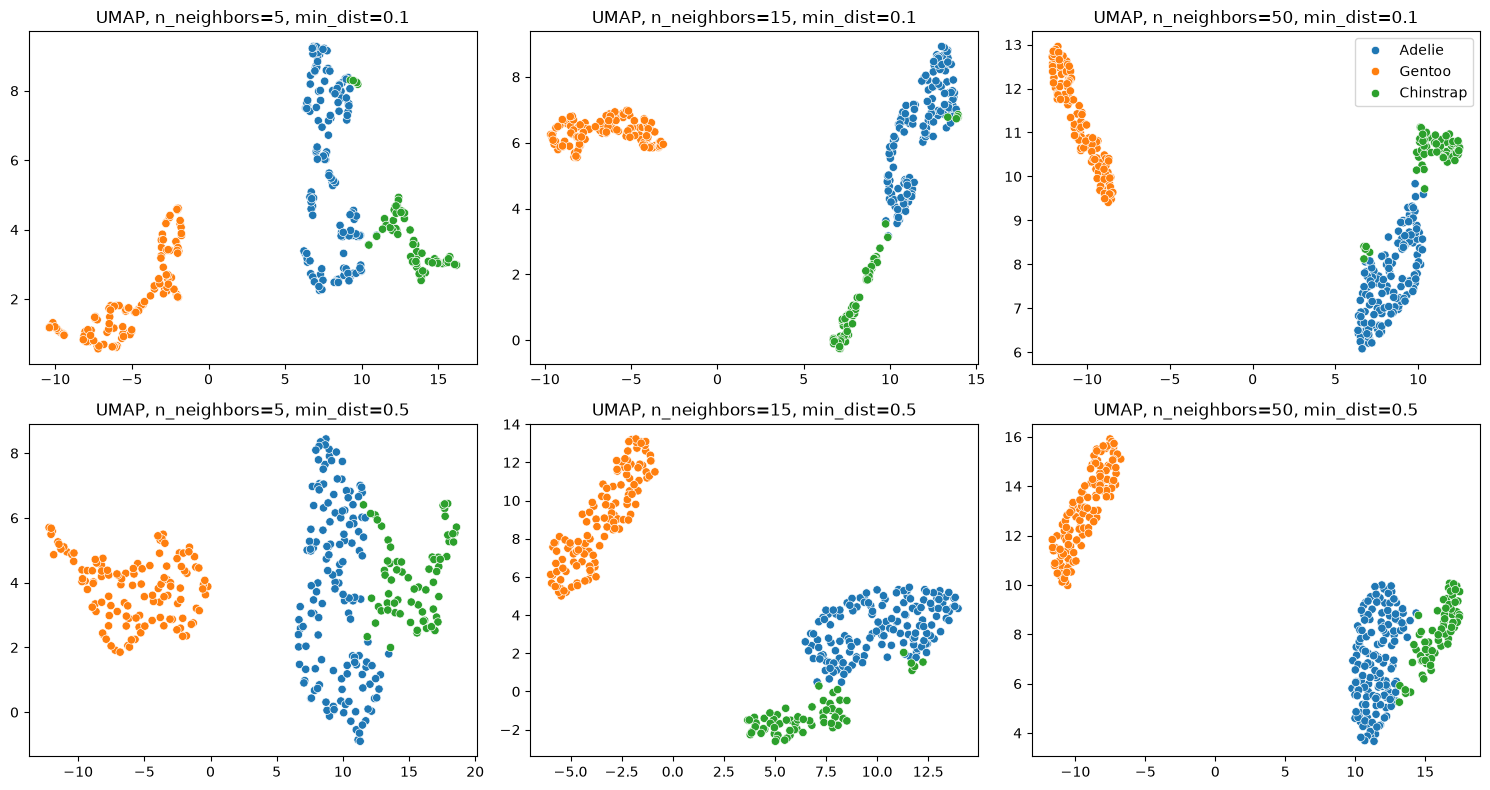

In [13]:
# YOUR CODE HERE
# varying perplexity in tsne
perplexities = [5, 30, 50]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, p in zip(axes, perplexities):
    tsne = TSNE(n_components=2, perplexity=p, random_state=42).fit_transform(X_scaled)
    sns.scatterplot(x=tsne[:, 0], y=tsne[:, 1], hue=labels, ax=ax, legend=(p == perplexities[0]))
    ax.set_title(f"t-SNE, perplexity={p}")
plt.tight_layout()
plt.show()

# varying distance and n_neighbors in umap
n_neighbors_list = [5, 15, 50]
min_dists = [0.1, 0.5]
fig, axes = plt.subplots(len(min_dists), len(n_neighbors_list), figsize=(15, 8))
for i, md in enumerate(min_dists):
    for j, nn in enumerate(n_neighbors_list):
        ax = axes[i, j]
        X_umap = umap.UMAP(n_components=2, n_neighbors=nn, min_dist=md,
                        random_state=42).fit_transform(X_scaled)
        sns.scatterplot(x=X_umap[:, 0], y=X_umap[:, 1], hue=labels, ax=ax,
                        legend=(i == 0 and j == len(n_neighbors_list) - 1))
        ax.set_title(f"UMAP, n_neighbors={nn}, min_dist={md}")
plt.tight_layout()
plt.show()

After generating the plots, describe the main changes you observe in the visualizations:
- How do the clusters shift, stretch, or separate as hyperparameters change?
- Which settings appear to better preserve the structure of the data?

Elaborate on your observations and support your discussion with specific visual examples.

It appears that for t-SNE, increasing the perplexity hyperparameter provided clearer, more defined clusters. For example, perplexity=5 provided many small "islands," and p=30 gave clear 3 groups that p=50 defined even better. With UMAP, the same pattern appears with n_neighbors as did with t-SNE's perplexity (there was more coherence groups instead of fragments, but overlap still occurred). As for min_dist, points were more packed together with lower min_distance parameters.

## 3. Apply to Real Data (1000 Genomes Subset) (25 points)

Your goal in this section is to try to create a figure similar to Figure 1 of the Diaz-Papkovich *et al.* (2019) paper, using a subset of genotype data from the 1000 Genomes Project.

To do so, complete the following steps:

a. Load the genotype dataset accompanying this lab, where each row corresponds to an individual, and each column to a genetic variant. Load also the provided population labels for each individual. 

b. **Standardize** the features (i.e., transform the genotype values to have zero mean and unit variance).

c. Apply **PCA**, **t-SNE**, and **UMAP** to reduce the data to 2 dimensions. You may use the default values for the rest of hyperparameters in these techniques. 

d. Create **scatter plots** of the resulting projections, coloring each point according to its **population group**.

e. Reflect on the following questions:
- Explain what you observe in each case. Additionally, which method appears to provide the best visual separation of the population into distinct groups? Elaborate on why this might be the case, based on what you know about each method.
- What changes if you first reduce the data to the **top 25 PCA components**, and then apply t-SNE or UMAP?
- In your opinion, what are the trade-offs between **interpretability** (e.g., preservation of local and global structure) and **performance** (e.g., visual separation of known populations and computational time) when using these dimensionality reduction methods?

Please elaborate on your answers and use the plots to support your discussion.

Shape of genomic_data: (3450, 868)
Shape of pop_labels: (3450,)


/Users/pacoherrera/Downloads/DataScience/Semester 3/Machine Learning/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


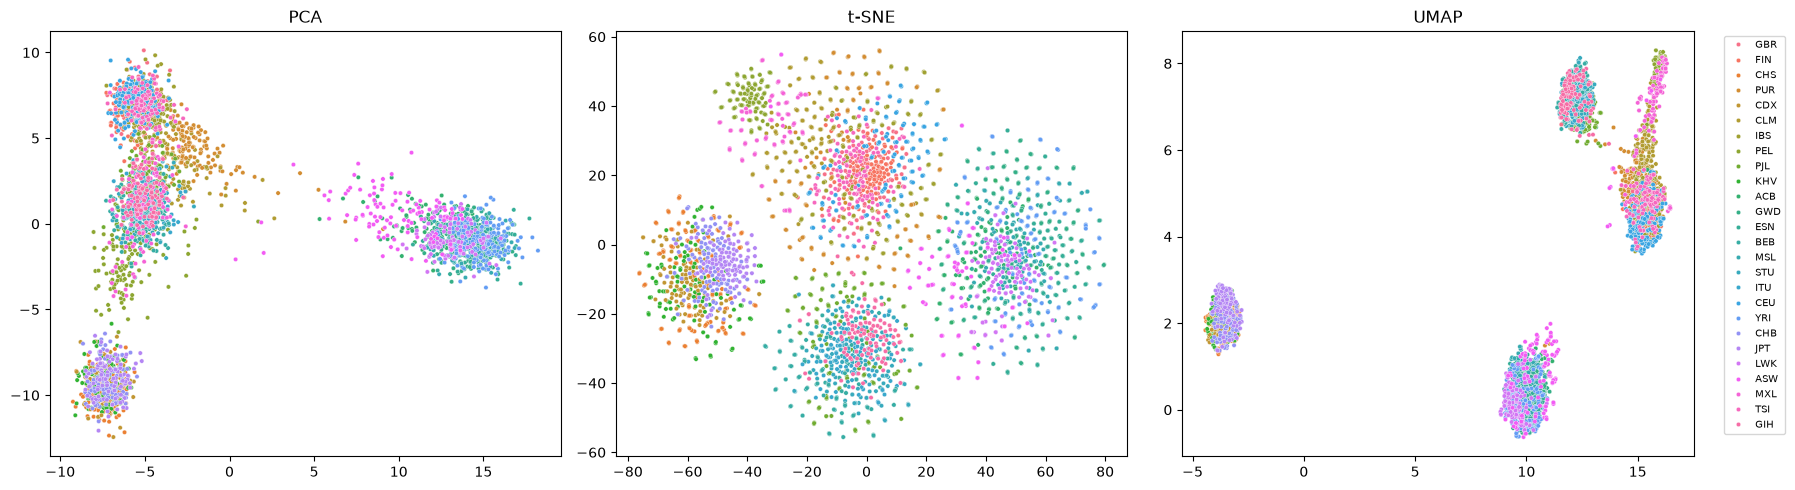

In [11]:
# YOUR CODE HERE

# a. loading data
genomic_data = np.load("genome_data_lab3.npy")
print("Shape of genomic_data:", genomic_data.shape)
pop_labels = np.loadtxt("population_labels_lab3.txt", dtype=str)
print("Shape of pop_labels:", pop_labels.shape)

# b. standardizing the data
genomic_data_scaled = StandardScaler().fit_transform(genomic_data)

# c. applying methods
gen_data_pca = PCA(n_components=2, random_state=42).fit_transform(genomic_data_scaled)
gen_data_tsne = TSNE(n_components=2, random_state=42).fit_transform(genomic_data_scaled)
gen_data_umap = umap.UMAP(n_components=2, random_state=42).fit_transform(genomic_data_scaled)

# d. visualizing the results
plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
sns.scatterplot(x=gen_data_pca[:, 0], y=gen_data_pca[:, 1], hue=pop_labels, s=10, legend=False)
plt.title("PCA")

plt.subplot(1, 3, 2)
sns.scatterplot(x=gen_data_tsne[:, 0], y=gen_data_tsne[:, 1], hue=pop_labels, s=10, legend=False)
plt.title("t-SNE")

plt.subplot(1, 3, 3)
sns.scatterplot(x=gen_data_umap[:, 0], y=gen_data_umap[:, 1], hue=pop_labels, s=10)
plt.title("UMAP")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=7)
    # mess w the legend

plt.tight_layout()
plt.show()


/Users/pacoherrera/Downloads/DataScience/Semester 3/Machine Learning/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


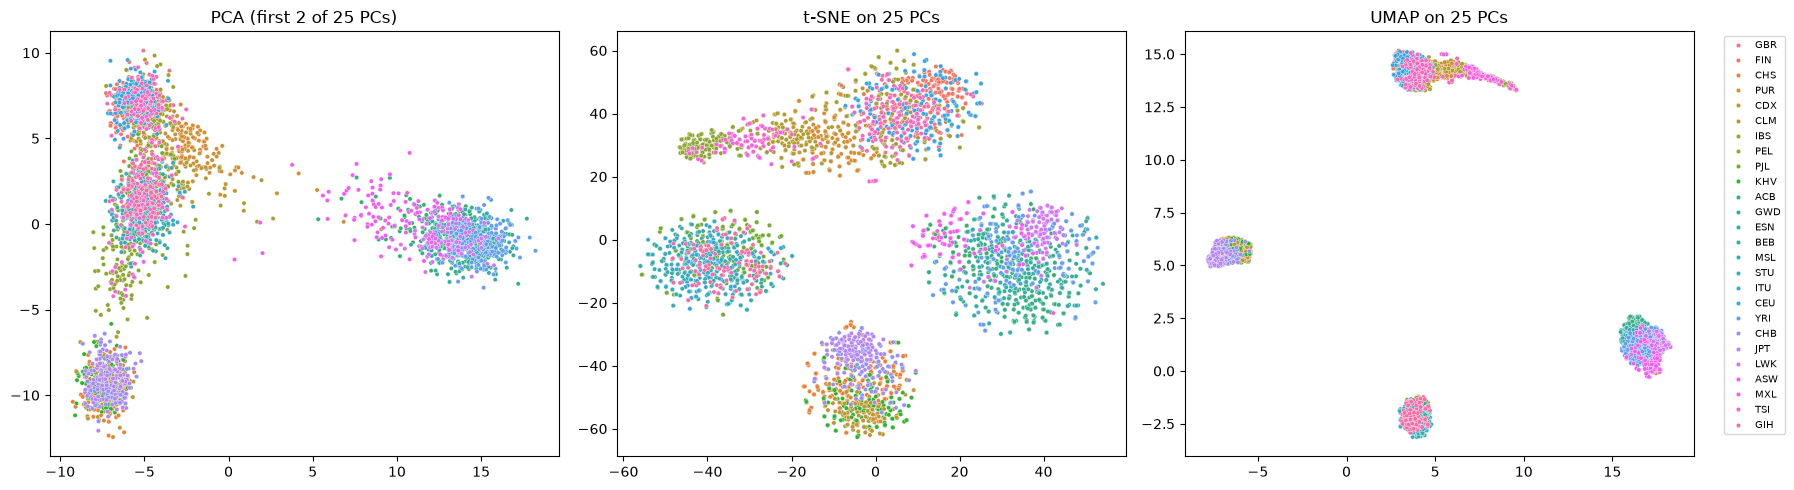

In [12]:
# e. reduce to top 25 PCs first
gen_data_pca25 = PCA(n_components=25, random_state=42).fit_transform(genomic_data_scaled)
gen_data_tsne25 = TSNE(n_components=2, random_state=42).fit_transform(gen_data_pca25)
gen_data_umap25 = umap.UMAP(n_components=2, random_state=42).fit_transform(gen_data_pca25)

plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
sns.scatterplot(x=gen_data_pca25[:, 0], y=gen_data_pca25[:, 1], hue=pop_labels, s=10, legend=False)
plt.title("PCA (first 2 of 25 PCs)")

plt.subplot(1, 3, 2)
sns.scatterplot(x=gen_data_tsne25[:, 0], y=gen_data_tsne25[:, 1], hue=pop_labels, s=10, legend=False)
plt.title("t-SNE on 25 PCs")

plt.subplot(1, 3, 3)
sns.scatterplot(x=gen_data_umap25[:, 0], y=gen_data_umap25[:, 1], hue=pop_labels, s=10)
plt.title("UMAP on 25 PCs")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=7)

plt.tight_layout()
plt.show()

## 4. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE